In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import math

In [2]:
df = pd.read_excel("Cleaned_DataV4.xlsx")

In [ ]:
df.head()

In [5]:
df_analysis = df.copy()

In [6]:
# Đảm bảo cột Ngày nhập học là datetime
df_analysis["Ngày nhập học"] = pd.to_datetime(
    df_analysis["Ngày nhập học"],
    errors="coerce",
    dayfirst=True
)

# Tách ngày - tháng - năm
df_analysis["Ngày nhập học_Ngày"] = df_analysis["Ngày nhập học"].dt.day
df_analysis["Ngày nhập học_Tháng"] = df_analysis["Ngày nhập học"].dt.month
df_analysis["Ngày nhập học_Năm"] = df_analysis["Ngày nhập học"].dt.year

In [8]:
df_analysis["Ngày nhập học_Thứ"] = (
    df_analysis["Ngày nhập học"]
    .dt.dayofweek
    .map({
        0: "Thứ 2",
        1: "Thứ 3",
        2: "Thứ 4",
        3: "Thứ 5",
        4: "Thứ 6",
        5: "Thứ 7",
        6: "Chủ nhật"
    })
)

In [10]:
df_analysis[
    [
        "Ngày nhập học",
        "Ngày nhập học_Ngày",
        "Ngày nhập học_Tháng",
        "Ngày nhập học_Năm",
        "Ngày nhập học_Thứ"
    ]
].head(10)

,Ngày nhập học,Ngày nhập học_Ngày,Ngày nhập học_Tháng,Ngày nhập học_Năm,Ngày nhập học_Thứ
0,2020-11-13,13,11,2020,Thứ 6
1,2020-02-07,7,2,2020,Thứ 6
2,2020-07-20,20,7,2020,Thứ 2
3,2020-08-14,14,8,2020,Thứ 6
4,2020-07-17,17,7,2020,Thứ 6
5,2020-08-07,7,8,2020,Thứ 6
6,2020-07-09,9,7,2020,Thứ 5
7,2020-06-29,29,6,2020,Thứ 2
8,2020-08-20,20,8,2020,Thứ 5
9,2020-03-08,8,3,2020,Chủ nhật


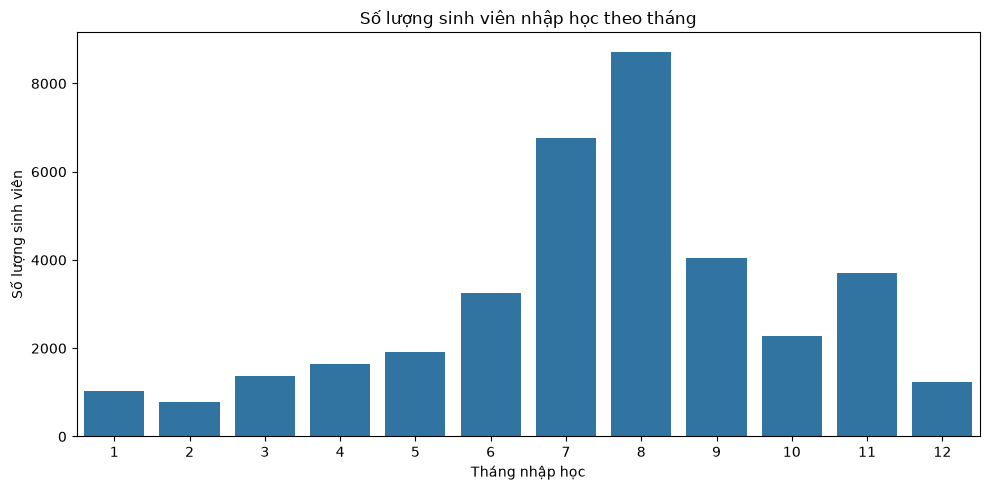

In [11]:
# 1. Số lượng sinh viên nhập học theo tháng
month_count = (
    df_analysis["Ngày nhập học_Tháng"]
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(10, 5))

sns.barplot(
    x=month_count.index,
    y=month_count.values
)

plt.title("Số lượng sinh viên nhập học theo tháng")
plt.xlabel("Tháng nhập học")
plt.ylabel("Số lượng sinh viên")

plt.tight_layout()
plt.show()

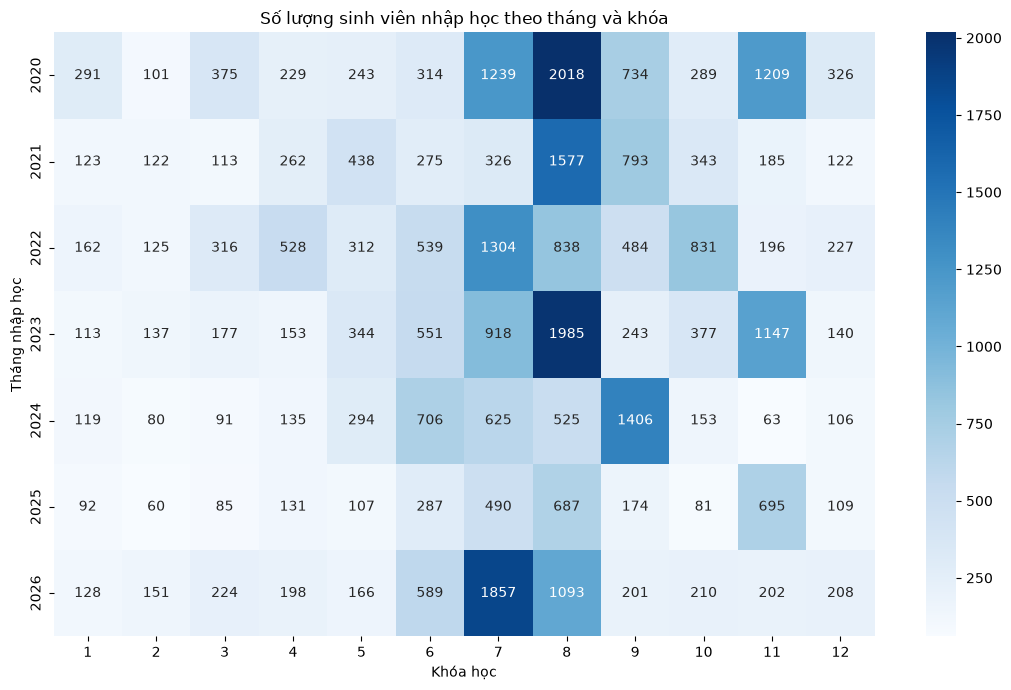

In [13]:
# 2. Bảng Tháng nhập học × Khóa học
month_year = pd.crosstab(
    df_analysis["Ngày nhập học_Tháng"],
    df_analysis["Khóa học"]
)

plt.figure(figsize=(11, 7))

sns.heatmap(
    month_year.T,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Số lượng sinh viên nhập học theo tháng và khóa")
plt.xlabel("Khóa học")
plt.ylabel("Tháng nhập học")

plt.tight_layout()
plt.show()

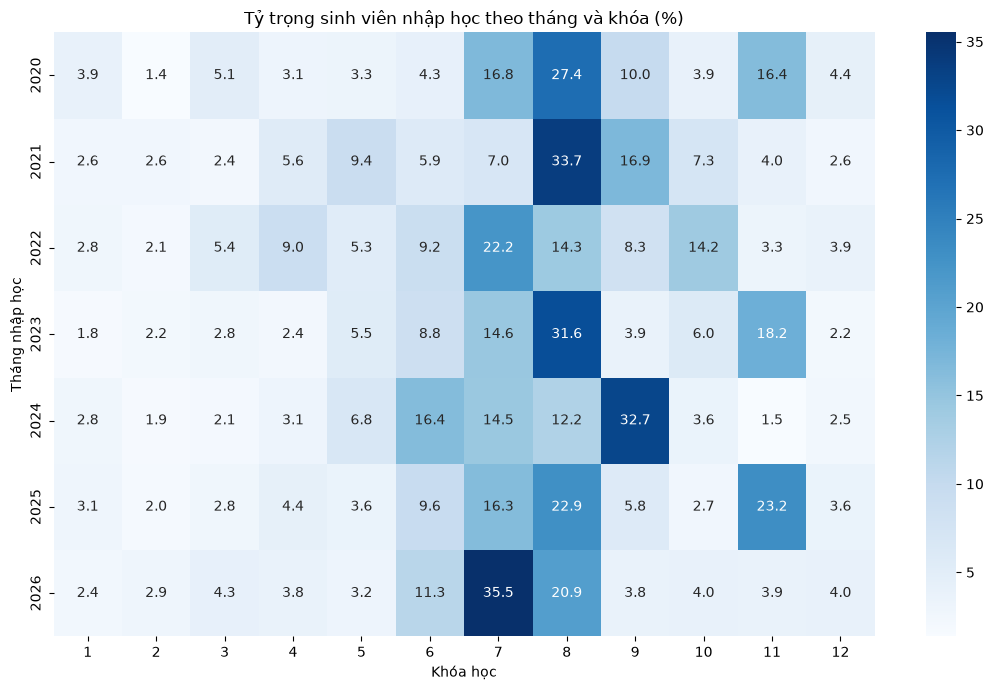

In [16]:
# 3. Tỷ trọng tháng nhập học trong từng khóa
month_year_pct = (
    month_year
    .div(month_year.sum(axis=0), axis=1)
    * 100
)

plt.figure(figsize=(11, 7))

sns.heatmap(
    month_year_pct.T,
    annot=True,
    fmt=".1f",
    cmap="Blues"
)

plt.title("Tỷ trọng sinh viên nhập học theo tháng và khóa (%)")
plt.xlabel("Khóa học")
plt.ylabel("Tháng nhập học")

plt.tight_layout()
plt.show()

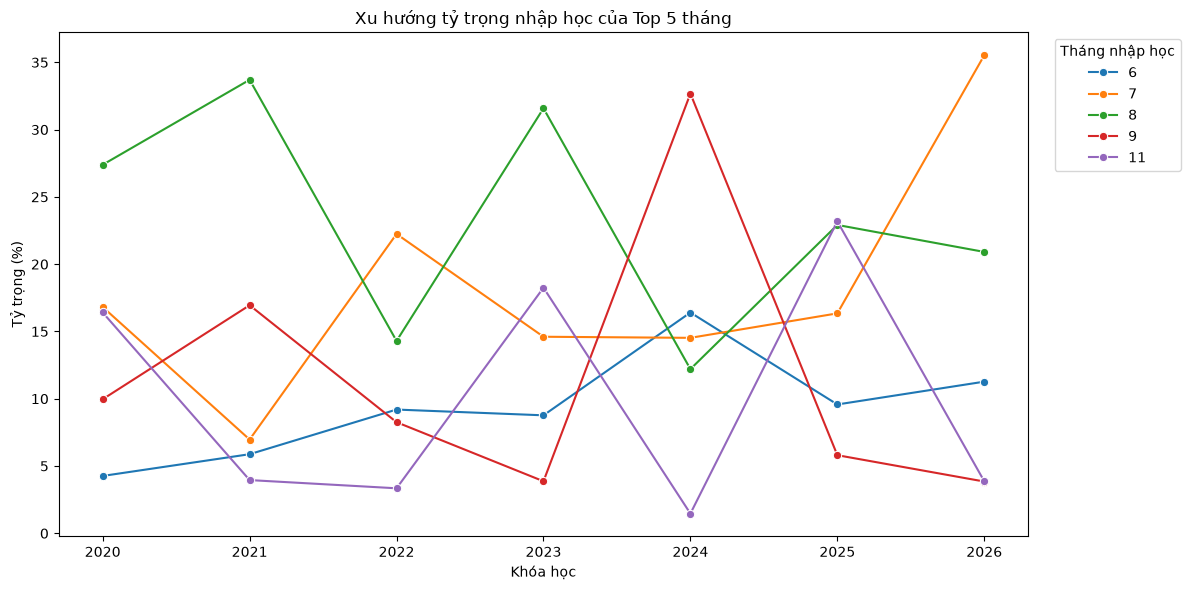

In [20]:
top5_month = (
    df_analysis["Ngày nhập học_Tháng"]
    .value_counts()
    .head(5)
    .index
)

temp = month_year_pct_long[
    month_year_pct_long["Ngày nhập học_Tháng"].isin(top5_month)
]

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=temp,
    x="Khóa học",
    y="Tỷ trọng (%)",
    hue="Ngày nhập học_Tháng",
    marker="o",
    palette="tab10"
)

plt.title("Xu hướng tỷ trọng nhập học của Top 5 tháng")
plt.xlabel("Khóa học")
plt.ylabel("Tỷ trọng (%)")

plt.xticks(sorted(df_analysis["Khóa học"].unique()))

plt.legend(
    title="Tháng nhập học",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

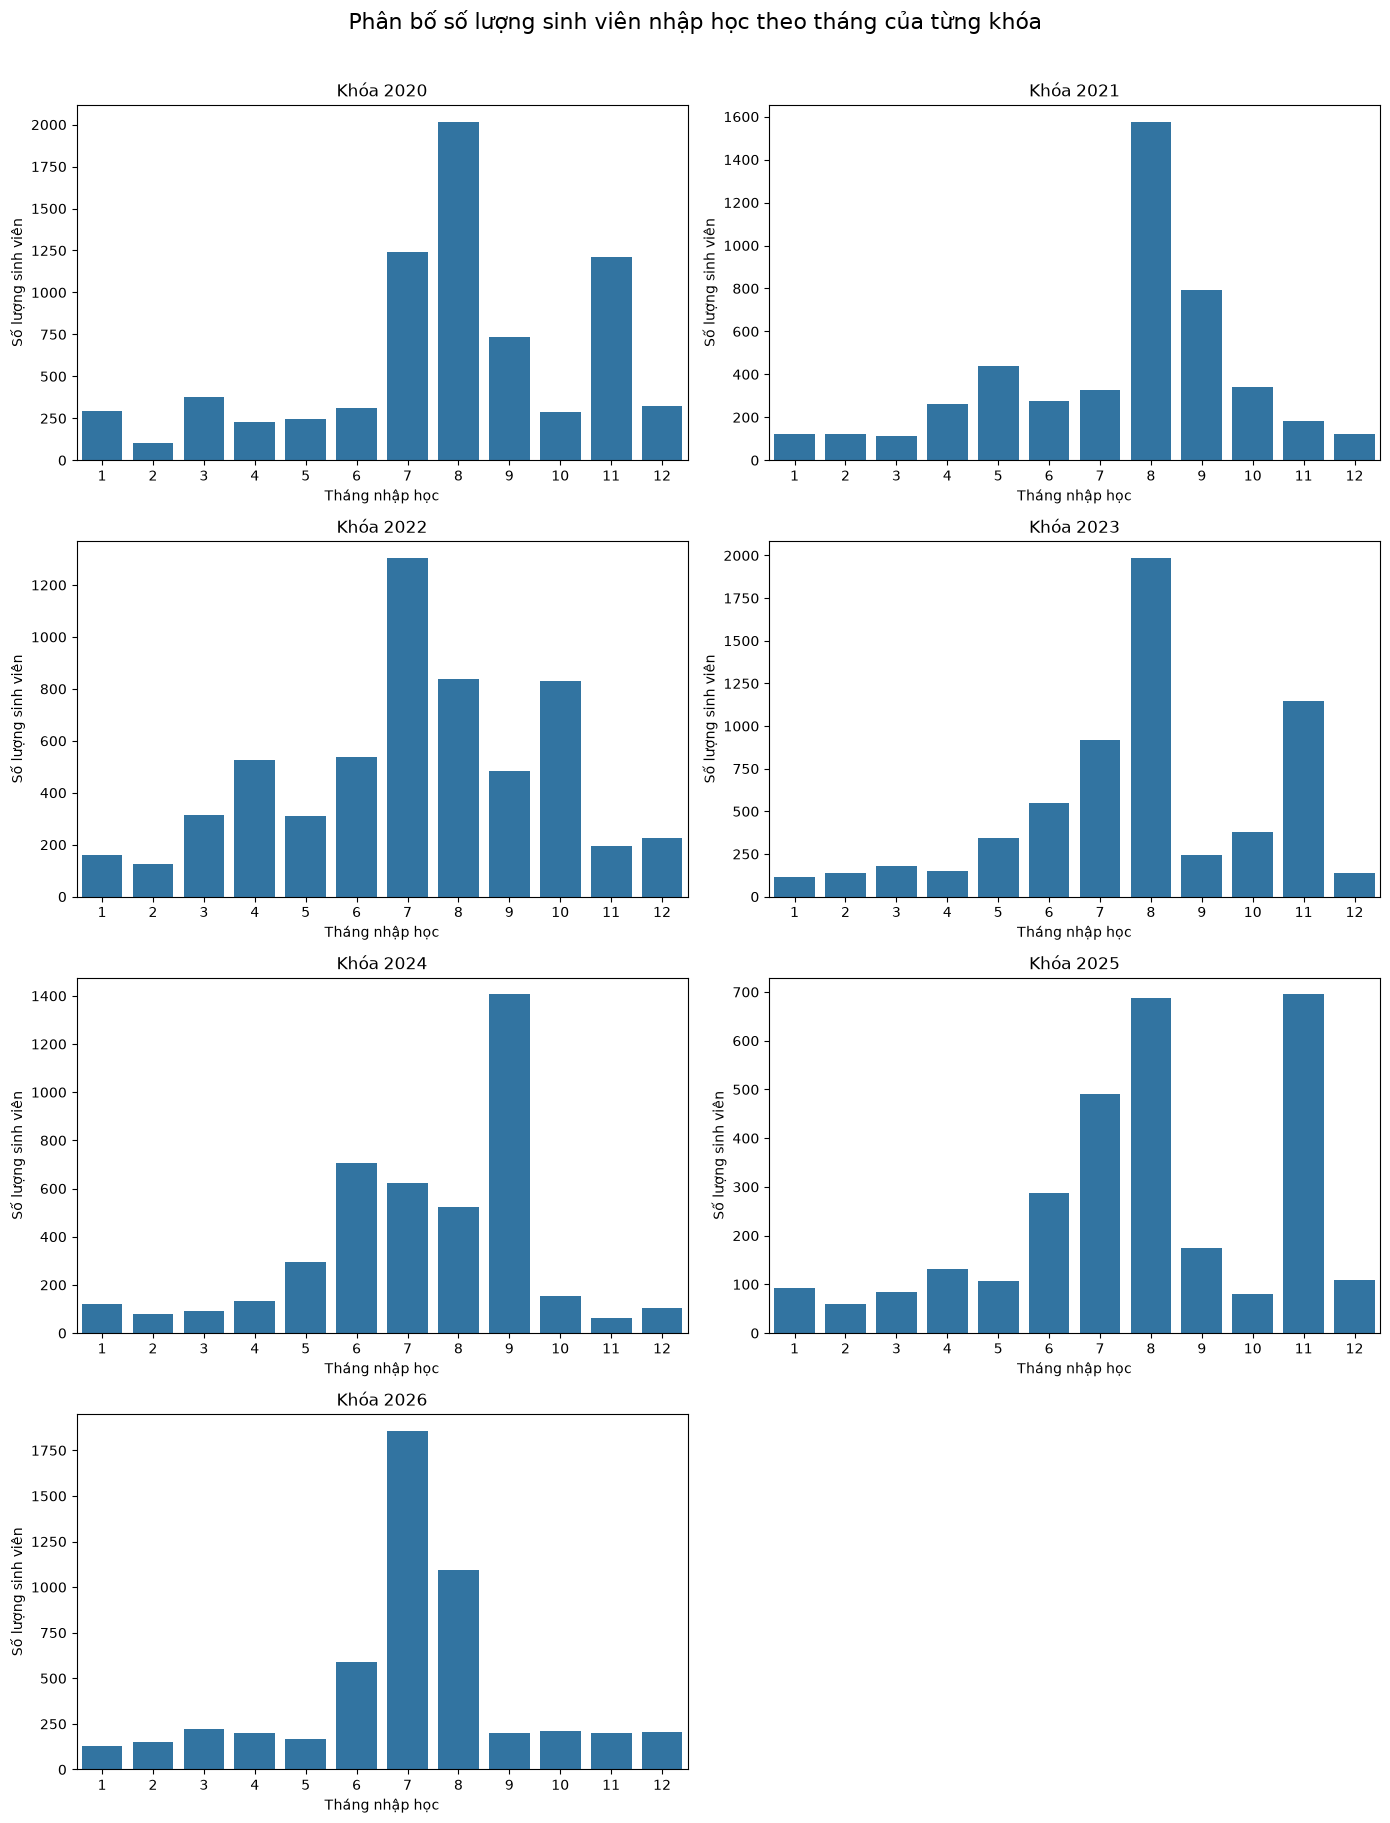

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns

years = sorted(df_analysis["Khóa học"].dropna().unique())

fig, axes = plt.subplots(
    nrows=4,
    ncols=2,
    figsize=(14, 18)
)

axes = axes.flatten()

for i, year in enumerate(years):
    
    # Lọc theo khóa
    temp = df_analysis[
        df_analysis["Khóa học"] == year
    ]
    
    # Đếm số SV theo tháng
    month_count = (
        temp["Ngày nhập học_Tháng"]
        .value_counts()
        .reindex(range(1, 13), fill_value=0)
    )
    
    sns.barplot(
        x=month_count.index,
        y=month_count.values,
        ax=axes[i]
    )
    
    axes[i].set_title(f"Khóa {int(year)}")
    axes[i].set_xlabel("Tháng nhập học")
    axes[i].set_ylabel("Số lượng sinh viên")
    axes[i].set_xticks(range(12))
    axes[i].set_xticklabels(range(1, 13))

# Vì grid 4x2 có 8 ô nhưng chỉ có 7 khóa
for j in range(len(years), len(axes)):
    axes[j].axis("off")

fig.suptitle(
    "Phân bố số lượng sinh viên nhập học theo tháng của từng khóa",
    fontsize=16,
    y=1.01
)

plt.tight_layout()
plt.show()

In [24]:
top5_month = (
    df_analysis["Ngày nhập học_Tháng"]
    .value_counts()
    .head(5)
    .index
)

df_top5_month = df_analysis[
    df_analysis["Ngày nhập học_Tháng"].isin(top5_month)
].copy()

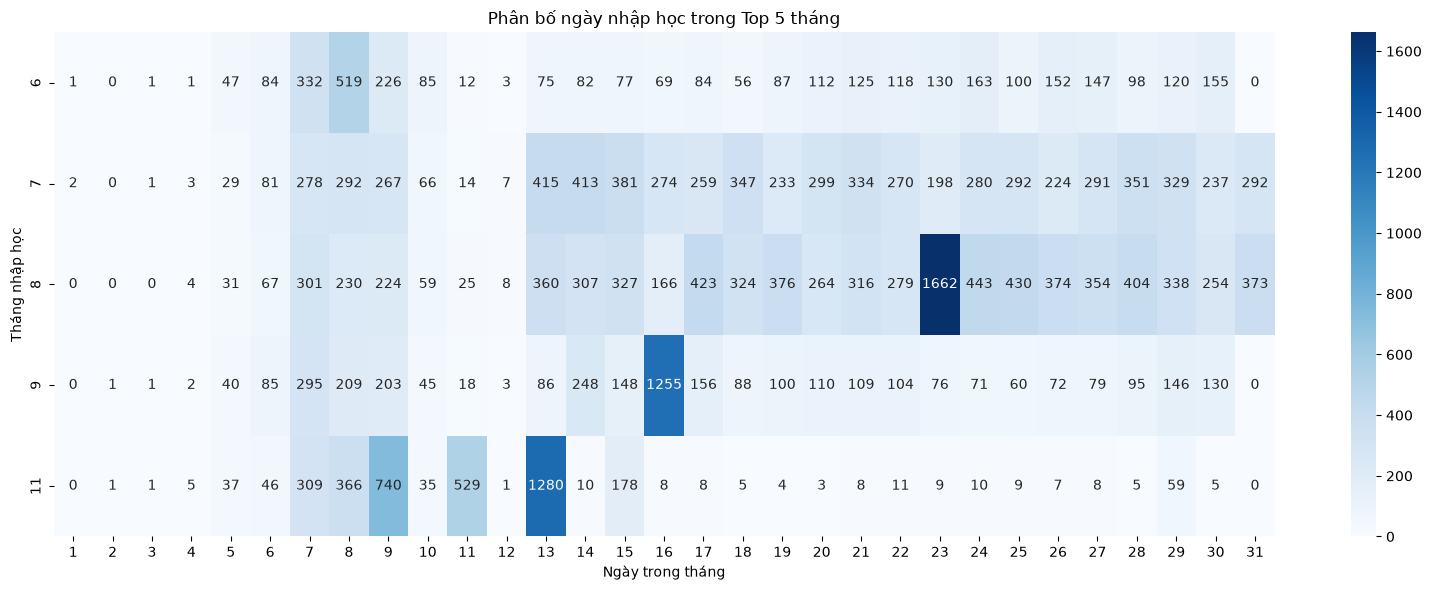

In [25]:
month_day = pd.crosstab(
    df_top5_month["Ngày nhập học_Tháng"],
    df_top5_month["Ngày nhập học_Ngày"]
)

# Sắp xếp tháng
month_day = month_day.sort_index()

plt.figure(figsize=(16, 6))

sns.heatmap(
    month_day,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Phân bố ngày nhập học trong Top 5 tháng")
plt.xlabel("Ngày trong tháng")
plt.ylabel("Tháng nhập học")

plt.tight_layout()
plt.show()

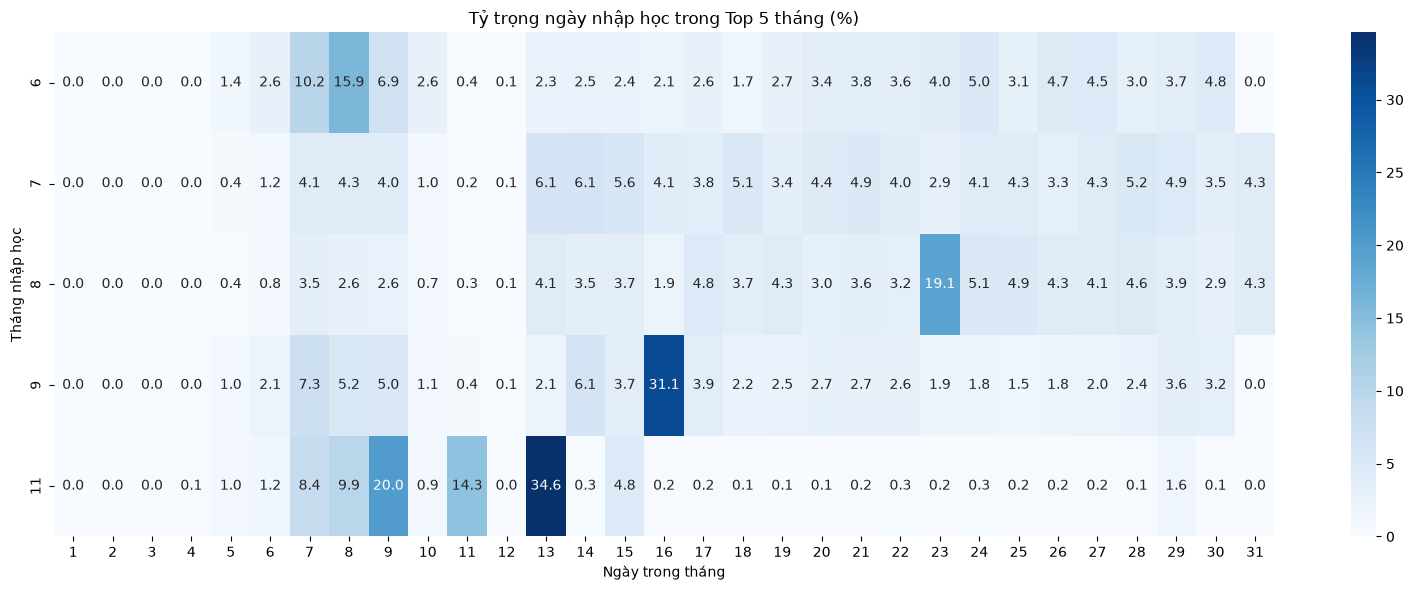

In [26]:
month_day_pct = (
    month_day
    .div(month_day.sum(axis=1), axis=0)
    * 100
)

plt.figure(figsize=(16, 6))

sns.heatmap(
    month_day_pct,
    annot=True,
    fmt=".1f",
    cmap="Blues"
)

plt.title("Tỷ trọng ngày nhập học trong Top 5 tháng (%)")
plt.xlabel("Ngày trong tháng")
plt.ylabel("Tháng nhập học")

plt.tight_layout()
plt.show()

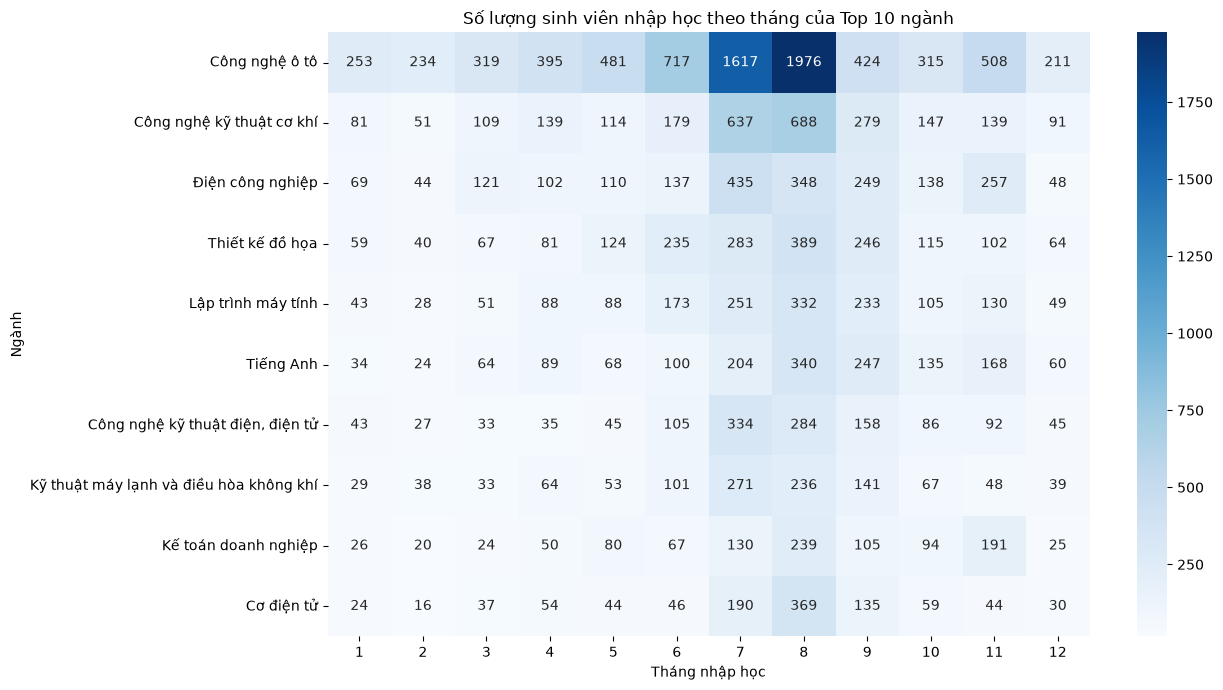

In [27]:
# Top 10 ngành có nhiều sinh viên nhất
top10_major = (
    df_analysis["Ngành"]
    .value_counts()
    .head(10)
    .index
)

# Lọc Top 10 ngành
temp = df_analysis[
    df_analysis["Ngành"].isin(top10_major)
].copy()

# Ngành × Tháng
major_month = pd.crosstab(
    temp["Ngành"],
    temp["Ngày nhập học_Tháng"]
)

# Giữ đúng thứ tự Top 10 ngành
major_month = major_month.reindex(top10_major)

plt.figure(figsize=(13, 7))

sns.heatmap(
    major_month,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Số lượng sinh viên nhập học theo tháng của Top 10 ngành")
plt.xlabel("Tháng nhập học")
plt.ylabel("Ngành")

plt.tight_layout()
plt.show()